RELIABILITY ANALYSIS - DATASET COMPARISON
Dataset 1: /ec/vol/enscal/VERIF_PrecipType/VERIF_ptype_all/DATA_preVerif/2024_2025_49r1/
Dataset 2: /ec/vol/enscal/VERIF_PrecipType/VERIF_ptype_all/DATA_preVerif/2021_2022/
Output path: ./verification_results/comparison/


LOADING DATASETS

Processing 2024-2025...
----------------------------------------------------------------------
   Found 140 files
   Loaded 9,882,615 matched pairs
   Period: 2024-11-12 to 2025-03-31
   Available types: Rain, Snow, Sleet, Freezing Rain, Freezing Drizzle, Ice Pellets
   ✓ Completed

Processing 2021-2022...
----------------------------------------------------------------------
   Found 162 files
   Loaded 10,360,420 matched pairs
   Period: 2021-10-21 to 2022-03-31
   ⚠️  Warning: 'freezdrizzle' not found in dataset, skipping
   Available types: Rain, Snow, Sleet, Freezing Rain, Ice Pellets
   ✓ Completed

Common precipitation types to compare: Rain, Snow, Sleet, Freezing Rain, Ice Pellets

CREATING COMPARISO

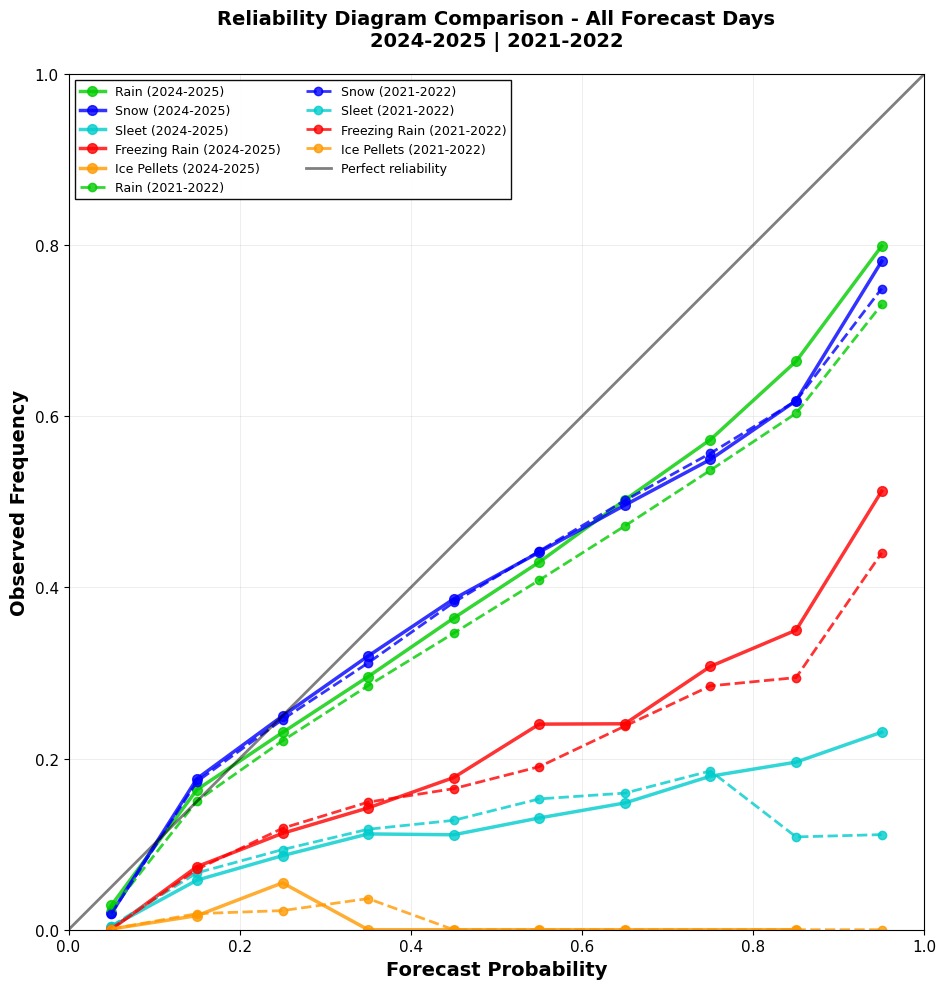

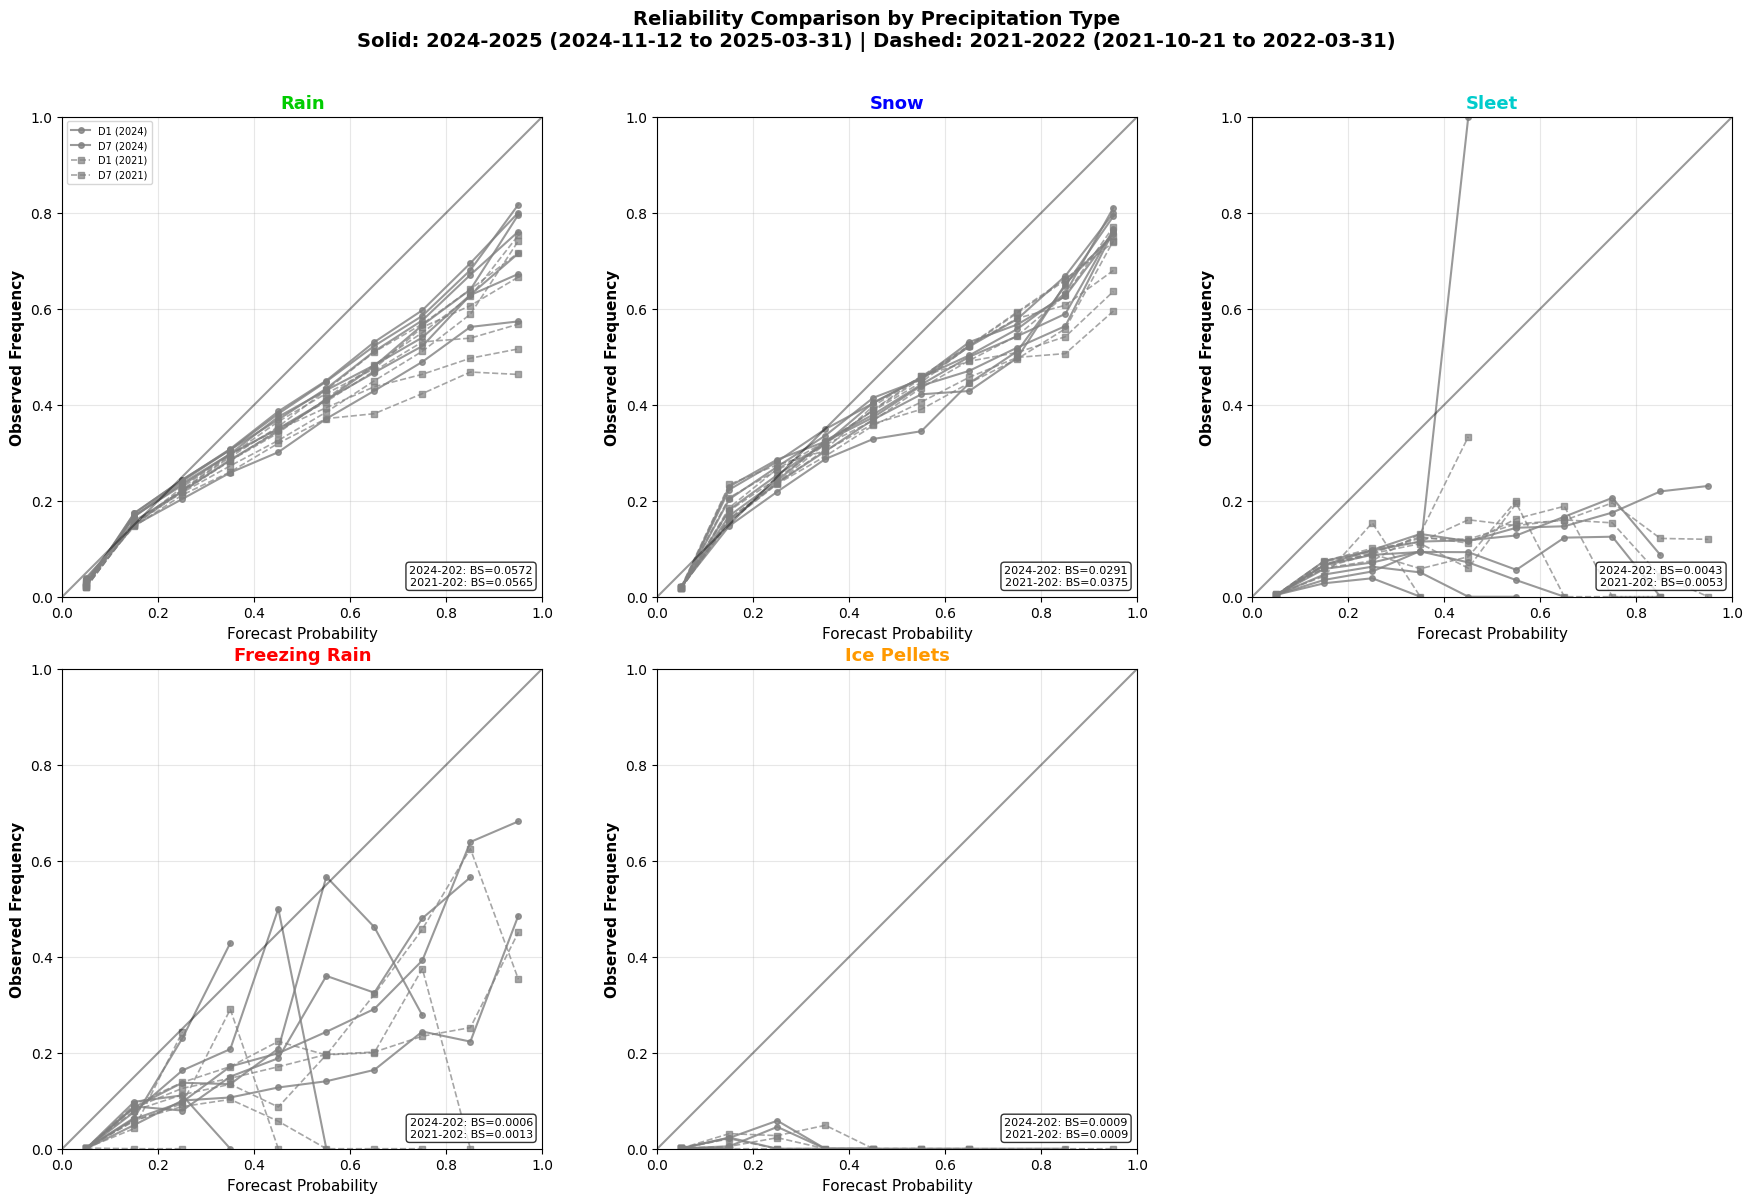

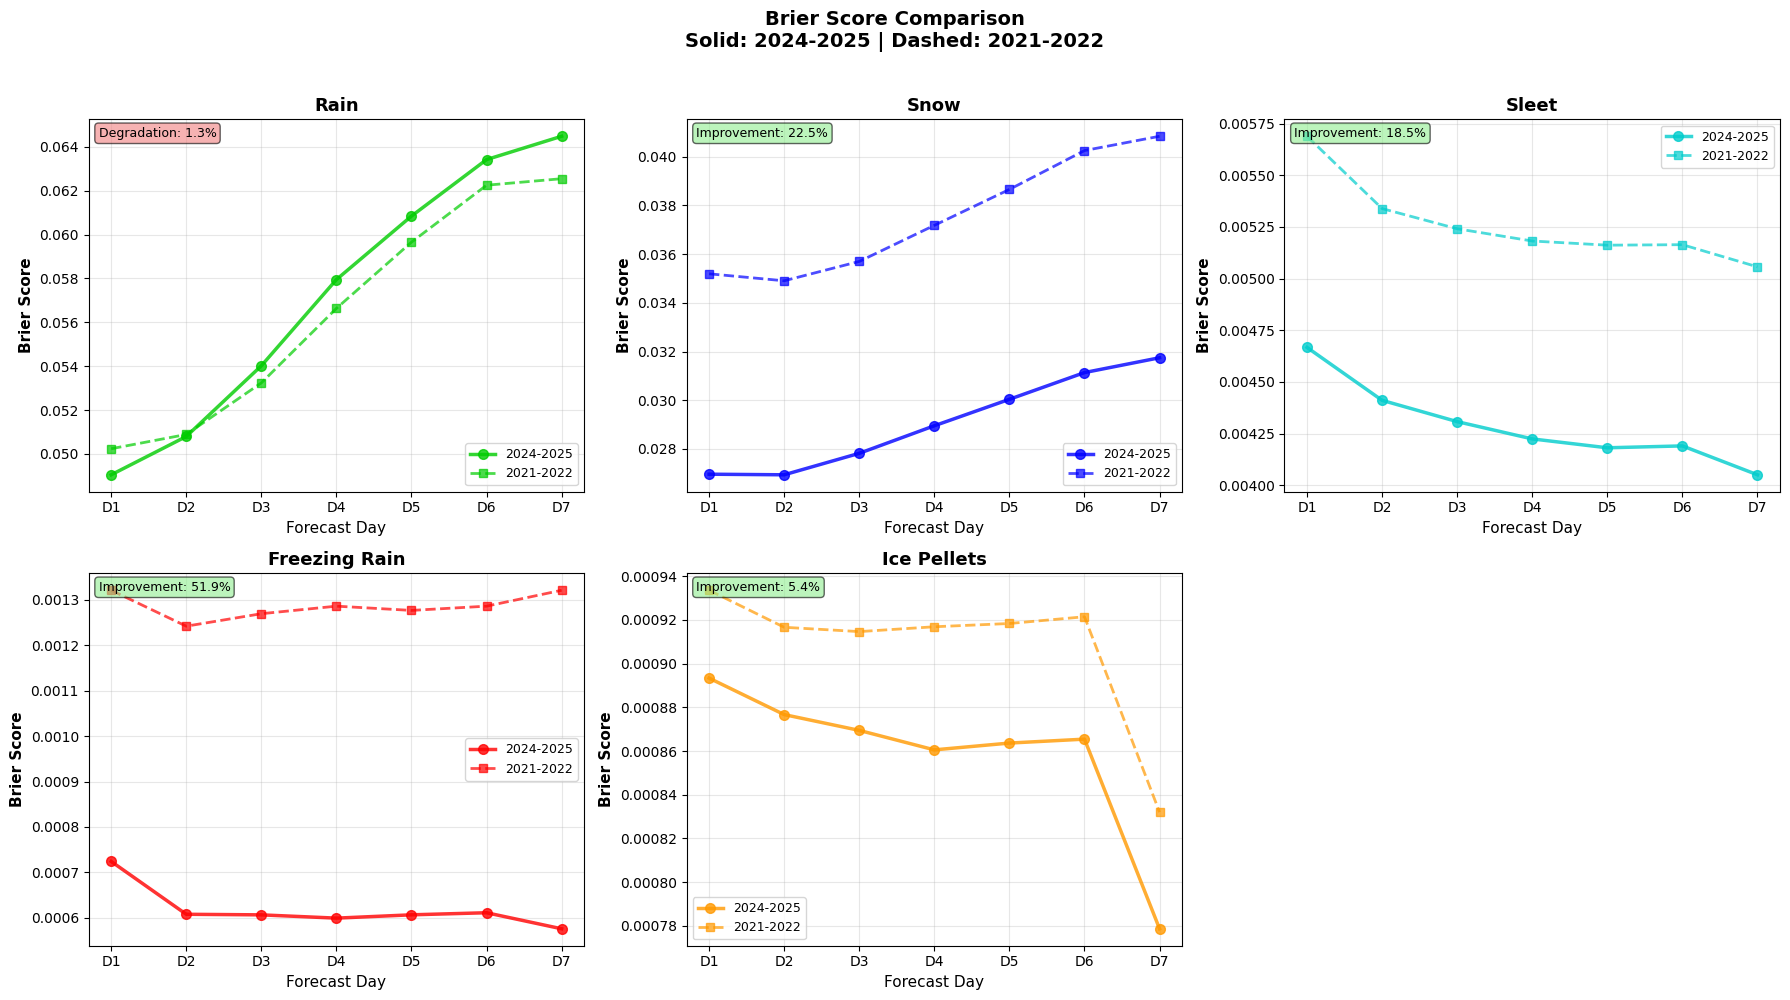

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import brier_score_loss
import glob
from datetime import datetime
import os

#
# RELIABILITY ANALYSIS - DATASET COMPARISON
# ------------------------------------------
#
# Compares reliability between two verification datasets
# Dataset 1: Solid lines
# Dataset 2: Dashed lines
#
########################################

# ===== CONFIGURATION =====
# Two datasets to compare
DATA_PATH_1 = "/ec/vol/enscal/VERIF_PrecipType/VERIF_ptype_all/DATA_preVerif/2024_2025_49r1/"
DATA_PATH_2 = "/ec/vol/enscal/VERIF_PrecipType/VERIF_ptype_all/DATA_preVerif/2021_2022/"

# Labels for datasets
LABEL_1 = "2024-2025"
LABEL_2 = "2021-2022"

OUTPUT_PATH = "./verification_results/comparison/"

if not os.path.exists(OUTPUT_PATH):
    os.makedirs(OUTPUT_PATH, exist_ok=True)

PRECIP_TYPES = ['rain', 'snow', 'sleet', 'freezrain', 'freezdrizzle', 'icepellets']

COLORS = {
    'rain': '#00CC00',
    'snow': '#0000FF',
    'sleet': '#00CCCC',
    'freezrain': '#FF0000',
    'freezdrizzle': '#FF1493',
    'icepellets': '#FF9900'
}

NICE_NAMES = {
    'rain': 'Rain',
    'snow': 'Snow',
    'sleet': 'Sleet',
    'freezrain': 'Freezing Rain',
    'freezdrizzle': 'Freezing Drizzle',
    'icepellets': 'Ice Pellets'
}

PROB_BINS = np.arange(0, 101, 10)

print("="*70)
print("RELIABILITY ANALYSIS - DATASET COMPARISON")
print("="*70)
print(f"Dataset 1: {DATA_PATH_1}")
print(f"Dataset 2: {DATA_PATH_2}")
print(f"Output path: {OUTPUT_PATH}")
print()

# Day groupings
day_groups = {
    1: [0, 3, 6, 9, 12, 15, 18, 21],
    2: [24, 27, 30, 33, 36, 39, 42, 45],
    3: [48, 51, 54, 57, 60, 63, 66, 69],
    4: [72, 75, 78, 81, 84, 87, 90, 93],
    5: [96, 99, 102, 105, 108, 111, 114, 117],
    6: [120, 123, 126, 129, 132, 135, 138, 141],
    7: [144, 150, 156, 162, 168]
}

days = sorted(day_groups.keys())

# ===== FUNCTION TO LOAD AND PROCESS DATASET =====
def load_and_process_dataset(data_path, label):
    """Load data and calculate reliability metrics"""
    
    print(f"\nProcessing {label}...")
    print("-" * 70)
    
    # Load data
    files = sorted(glob.glob(data_path + "matched_pairs_*.parquet"))
    print(f"   Found {len(files)} files")
    
    if len(files) == 0:
        print(f"   ERROR: No files found!")
        return None
    
    df = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)
    print(f"   Loaded {len(df):,} matched pairs")
    
    # Extract verification period
    start_date = df['forecast_date'].min()
    end_date = df['forecast_date'].max()
    start_date_str = f"{str(start_date)[:4]}-{str(start_date)[4:6]}-{str(start_date)[6:]}"
    end_date_str = f"{str(end_date)[:4]}-{str(end_date)[4:6]}-{str(end_date)[6:]}"
    period_str = f"{start_date_str} to {end_date_str}"
    print(f"   Period: {period_str}")
    
    # Detect which precipitation types are available in this dataset
    available_types = []
    for ptype in PRECIP_TYPES:
        obs_col = f'obs_{ptype}'
        prob_col = f'prob_{ptype}'
        if obs_col in df.columns and prob_col in df.columns:
            available_types.append(ptype)
        else:
            print(f"   ⚠️  Warning: '{ptype}' not found in dataset, skipping")
    
    print(f"   Available types: {', '.join([NICE_NAMES[p] for p in available_types])}")
    
    # Calculate reliability for each day
    reliability_data = {ptype: {day: {'bins': [], 'obs_freq': [], 'counts': []} 
                                for day in days} for ptype in available_types}
    
    brier_scores = {ptype: [] for ptype in available_types}
    
    for day in days:
        steps_in_day = day_groups[day]
        df_day = df[df['forecast_step'].isin(steps_in_day)]
        
        for ptype in available_types:
            obs_col = f'obs_{ptype}'
            prob_col = f'prob_{ptype}'
            
            obs = df_day[obs_col].values
            prob = df_day[prob_col].values
            
            # Remove NaN
            valid_mask = ~np.isnan(prob)
            obs_valid = obs[valid_mask]
            prob_valid = prob[valid_mask]
            
            if len(obs_valid) == 0:
                brier_scores[ptype].append(np.nan)
                continue
            
            # Brier Score
            prob_01 = prob_valid / 100.0
            bs = brier_score_loss(obs_valid, prob_01)
            brier_scores[ptype].append(bs)
            
            # Reliability curve
            bin_centers = []
            obs_freqs = []
            bin_counts = []
            
            for i in range(len(PROB_BINS) - 1):
                bin_start = PROB_BINS[i]
                bin_end = PROB_BINS[i + 1]
                bin_center = (bin_start + bin_end) / 2
                
                mask = (prob_valid >= bin_start) & (prob_valid < bin_end)
                if i == len(PROB_BINS) - 2:
                    mask = (prob_valid >= bin_start) & (prob_valid <= bin_end)
                
                n_in_bin = mask.sum()
                
                if n_in_bin > 0:
                    obs_freq = obs_valid[mask].mean()
                    bin_centers.append(bin_center)
                    obs_freqs.append(obs_freq)
                    bin_counts.append(n_in_bin)
            
            reliability_data[ptype][day]['bins'] = bin_centers
            reliability_data[ptype][day]['obs_freq'] = obs_freqs
            reliability_data[ptype][day]['counts'] = bin_counts
    
    print(f"   ✓ Completed")
    
    return {
        'reliability_data': reliability_data,
        'brier_scores': brier_scores,
        'period_str': period_str,
        'label': label,
        'available_types': available_types
    }

# ===== LOAD BOTH DATASETS =====
print("\n" + "="*70)
print("LOADING DATASETS")
print("="*70)

dataset1 = load_and_process_dataset(DATA_PATH_1, LABEL_1)
dataset2 = load_and_process_dataset(DATA_PATH_2, LABEL_2)

if dataset1 is None or dataset2 is None:
    print("\nERROR: Could not load one or both datasets!")
    exit(1)

# Find common precipitation types between both datasets
common_types = [p for p in dataset1['available_types'] if p in dataset2['available_types']]

if len(common_types) == 0:
    print("\nERROR: No common precipitation types between datasets!")
    exit(1)

print("\n" + "="*70)
print(f"Common precipitation types to compare: {', '.join([NICE_NAMES[p] for p in common_types])}")
print("="*70)

# ===== CREATE COMBINED RELIABILITY DIAGRAM =====
print("\n" + "="*70)
print("CREATING COMPARISON PLOTS")
print("="*70)
print()

print("1. Creating combined reliability diagram...")

fig, ax = plt.subplots(figsize=(12, 10))

# Plot both datasets
for dataset, linestyle, linewidth in [(dataset1, '-', 2.5), (dataset2, '--', 2.0)]:
    
    reliability_data = dataset['reliability_data']
    
    for ptype in common_types:  # Use common_types instead of PRECIP_TYPES
        # Aggregate across all days
        all_bins = []
        all_obs = []
        all_counts = []
        
        for day in days:
            bins = reliability_data[ptype][day]['bins']
            obs = reliability_data[ptype][day]['obs_freq']
            counts = reliability_data[ptype][day]['counts']
            
            all_bins.extend(bins)
            all_obs.extend(obs)
            all_counts.extend(counts)
        
        if len(all_bins) > 0:
            # Group by bins
            unique_bins = sorted(set(all_bins))
            bin_obs_freq = []
            
            for ub in unique_bins:
                indices = [i for i, b in enumerate(all_bins) if b == ub]
                total_count = sum([all_counts[i] for i in indices])
                weighted_obs = sum([all_obs[i] * all_counts[i] for i in indices]) / total_count
                bin_obs_freq.append(weighted_obs)
            
            # Plot
            label = f"{NICE_NAMES[ptype]} ({dataset['label']})"
            ax.plot([b/100 for b in unique_bins], bin_obs_freq, 
                    marker='o', 
                    linewidth=linewidth, 
                    markersize=7 if linestyle == '-' else 6,
                    linestyle=linestyle,
                    label=label,
                    color=COLORS[ptype],
                    alpha=0.8)

# Perfect reliability line
ax.plot([0, 1], [0, 1], 'k-', linewidth=2, label='Perfect reliability', alpha=0.5)

# Formatting
ax.set_xlabel('Forecast Probability', fontsize=14, fontweight='bold')
ax.set_ylabel('Observed Frequency', fontsize=14, fontweight='bold')
title_str = f'Reliability Diagram Comparison - All Forecast Days\n'
title_str += f'{LABEL_1} | {LABEL_2}'
ax.set_title(title_str, fontsize=14, fontweight='bold', pad=20)

ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
ax.set_aspect('equal')
ax.grid(True, alpha=0.3, linestyle='-', linewidth=0.5)
ax.set_axisbelow(True)

# Legend - split into two columns
ax.legend(loc='upper left', fontsize=9, framealpha=0.95, 
          edgecolor='black', fancybox=False, ncol=2)

ax.tick_params(axis='both', labelsize=11)

plt.tight_layout()
plt.savefig(OUTPUT_PATH + 'reliability_comparison_combined.png', dpi=300, bbox_inches='tight')
print(f"   Saved: {OUTPUT_PATH}reliability_comparison_combined.png")
print()

# ===== CREATE INDIVIDUAL COMPARISON PLOTS =====
print("2. Creating individual comparison plots...")

# Determine subplot layout based on number of common types
n_types = len(common_types)
if n_types <= 3:
    nrows, ncols = 1, n_types
elif n_types <= 6:
    nrows, ncols = 2, 3
else:
    nrows, ncols = 3, 3

fig, axes = plt.subplots(nrows, ncols, figsize=(6*ncols, 6*nrows))
if n_types == 1:
    axes = [axes]
else:
    axes = axes.flatten() if n_types > 1 else [axes]

title_str = f'Reliability Comparison by Precipitation Type\n'
title_str += f'Solid: {LABEL_1} ({dataset1["period_str"]}) | Dashed: {LABEL_2} ({dataset2["period_str"]})'
fig.suptitle(title_str, fontsize=14, fontweight='bold', y=0.995)

for idx, ptype in enumerate(common_types):  # Use common_types
    ax = axes[idx]
    
    # Plot both datasets
    for dataset, linestyle, alpha_val in [(dataset1, '-', 0.8), (dataset2, '--', 0.7)]:
        
        reliability_data = dataset['reliability_data']
        
        for day in days:
            bins = reliability_data[ptype][day]['bins']
            obs = reliability_data[ptype][day]['obs_freq']
            
            if len(bins) > 0:
                label = f'D{day} ({dataset["label"][:4]})' if day in [1, 7] else None
                ax.plot([b/100 for b in bins], obs, 
                        marker='o' if linestyle == '-' else 's',
                        linewidth=1.5 if linestyle == '-' else 1.2,
                        markersize=4,
                        linestyle=linestyle,
                        label=label,
                        alpha=alpha_val,
                        color='gray')
    
    # Perfect reliability line
    ax.plot([0, 1], [0, 1], 'k-', linewidth=1.5, alpha=0.4)
    
    # Formatting
    ax.set_xlabel('Forecast Probability', fontsize=11)
    ax.set_ylabel('Observed Frequency', fontsize=11, fontweight='bold')
    ax.set_title(NICE_NAMES[ptype], fontsize=13, fontweight='bold', color=COLORS[ptype])
    ax.set_xlim([0, 1])
    ax.set_ylim([0, 1])
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.3)
    if idx == 0:  # Only show legend on first plot
        ax.legend(loc='upper left', fontsize=7)
    
    # Show mean Brier Scores for both datasets
    bs1 = np.nanmean(dataset1['brier_scores'][ptype])
    bs2 = np.nanmean(dataset2['brier_scores'][ptype])
    textstr = f'{LABEL_1[:8]}: BS={bs1:.4f}\n{LABEL_2[:8]}: BS={bs2:.4f}'
    ax.text(0.98, 0.02, textstr, 
            transform=ax.transAxes, fontsize=8,
            verticalalignment='bottom', horizontalalignment='right',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# Hide unused subplots
for idx in range(len(common_types), len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.savefig(OUTPUT_PATH + 'reliability_comparison_individual.png', dpi=300, bbox_inches='tight')
print(f"   Saved: {OUTPUT_PATH}reliability_comparison_individual.png")
print()

# ===== CREATE BRIER SCORE COMPARISON =====
print("3. Creating Brier Score comparison...")

# Determine subplot layout based on number of common types
n_types = len(common_types)
if n_types <= 3:
    nrows, ncols = 1, n_types
elif n_types <= 6:
    nrows, ncols = 2, 3
else:
    nrows, ncols = 3, 3

fig, axes = plt.subplots(nrows, ncols, figsize=(6*ncols, 5*nrows))
if n_types == 1:
    axes = [axes]
else:
    axes = axes.flatten() if n_types > 1 else [axes]

title_str = f'Brier Score Comparison\n'
title_str += f'Solid: {LABEL_1} | Dashed: {LABEL_2}'
fig.suptitle(title_str, fontsize=14, fontweight='bold', y=0.995)

for idx, ptype in enumerate(common_types):  # Use common_types
    ax = axes[idx]
    
    # Plot both datasets
    bs1 = np.array(dataset1['brier_scores'][ptype])
    bs2 = np.array(dataset2['brier_scores'][ptype])
    
    ax.plot(days, bs1, marker='o', linewidth=2.5, markersize=7, 
            label=LABEL_1, color=COLORS[ptype], linestyle='-', alpha=0.8)
    ax.plot(days, bs2, marker='s', linewidth=2.0, markersize=6, 
            label=LABEL_2, color=COLORS[ptype], linestyle='--', alpha=0.7)
    
    ax.set_xlabel('Forecast Day', fontsize=11)
    ax.set_ylabel('Brier Score', fontsize=11, fontweight='bold')
    ax.set_title(NICE_NAMES[ptype], fontsize=13, fontweight='bold')
    ax.set_xticks(days)
    ax.set_xticklabels([f'D{d}' for d in days])
    ax.grid(True, alpha=0.3)
    ax.legend(loc='best', fontsize=9)
    
    # Show mean improvement
    mean_bs1 = np.nanmean(bs1)
    mean_bs2 = np.nanmean(bs2)
    improvement = ((mean_bs2 - mean_bs1) / mean_bs2) * 100 if mean_bs2 > 0 else 0
    
    if improvement > 0:
        color = 'lightgreen'
        text = f'Improvement: {improvement:.1f}%'
    elif improvement < 0:
        color = 'lightcoral'
        text = f'Degradation: {abs(improvement):.1f}%'
    else:
        color = 'lightyellow'
        text = 'No change'
    
    ax.text(0.02, 0.98, text, 
            transform=ax.transAxes, fontsize=9,
            verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor=color, alpha=0.6))

# Hide unused subplots
for idx in range(len(common_types), len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.savefig(OUTPUT_PATH + 'brier_comparison.png', dpi=300, bbox_inches='tight')
print(f"   Saved: {OUTPUT_PATH}brier_comparison.png")
print()

# ===== SUMMARY TABLE =====
print("="*70)
print("COMPARISON SUMMARY")
print("="*70)
print()
print(f"{'Type':<20} {LABEL_1 + ' BS':<15} {LABEL_2 + ' BS':<15} {'Difference':<15} {'Change %':<10}")
print("-"*80)

for ptype in common_types:  # Use common_types
    bs1 = np.nanmean(dataset1['brier_scores'][ptype])
    bs2 = np.nanmean(dataset2['brier_scores'][ptype])
    diff = bs1 - bs2
    change_pct = (diff / bs2) * 100 if bs2 > 0 else 0
    
    symbol = "↓" if diff < 0 else "↑" if diff > 0 else "="
    
    print(f"{NICE_NAMES[ptype]:<20} {bs1:>13.4f}  {bs2:>13.4f}  {diff:>13.4f} {symbol}  {change_pct:>8.1f}%")

print()
print("Interpretation:")
print("  ↓ Negative difference = Improvement (lower Brier Score is better)")
print("  ↑ Positive difference = Degradation")
print()
print(f"All plots saved to: {OUTPUT_PATH}")